### Bivariate Analysis

#### Keith R. Holdaway FGS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate synthetic petrophysical data
np.random.seed(42)

# First create independent arrays
nphi = np.random.uniform(0.1, 0.3, 1000)  # Neutron Porosity (v/v)
gr = np.random.normal(60, 15, 1000)       # Gamma Ray (API)

# Then create dependent arrays using the independent ones
rhob = 2.65 - 0.9 * nphi + np.random.normal(0, 0.05, 1000)  # Density (g/cc)
rt = 10 ** (2 - 0.5 * nphi + np.random.normal(0, 0.1, 1000))  # Resistivity (ohm-m)
facies = np.random.choice(['Sandstone', 'Shale', 'Carbonate'], 
                         p=[0.6, 0.3, 0.1], size=1000)

# Now combine into a dictionary
data = {
    'GR': gr,
    'NPHI': nphi,
    'RHOB': rhob,
    'RT': rt,
    'Facies': facies
}

# Create DataFrame
df = pd.DataFrame(data)

# Verify the first few rows
print(df.head())

          GR      NPHI      RHOB         RT     Facies
0  62.665515  0.174908  2.422267  99.999469  Sandstone
1  39.969835  0.290143  2.384716  61.652692  Carbonate
2  65.702968  0.246399  2.353005  57.079547  Sandstone
3  69.158786  0.219732  2.490244  61.084315  Sandstone
4  68.396857  0.131204  2.536039  76.856012  Sandstone


## Scatter Plots (Core Bivariate Analysis)

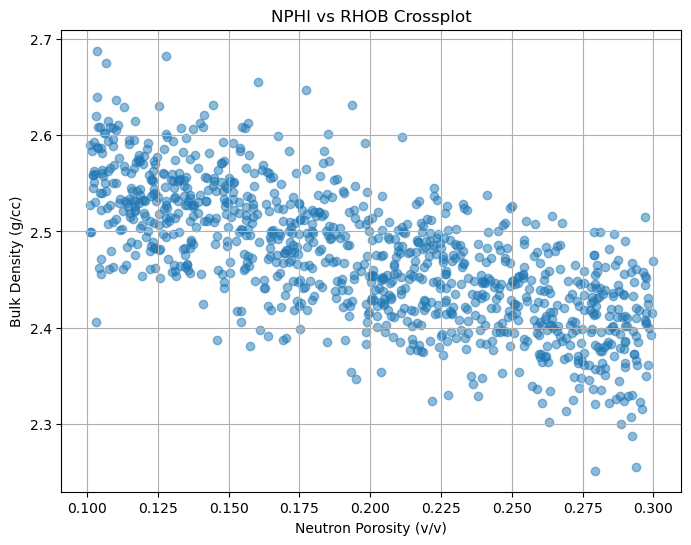

In [2]:
plt.figure(figsize=(8,6))
plt.scatter(df['NPHI'], df['RHOB'], alpha=0.5)
plt.title('NPHI vs RHOB Crossplot')
plt.xlabel('Neutron Porosity (v/v)')
plt.ylabel('Bulk Density (g/cc)')
plt.grid(True)
plt.show()

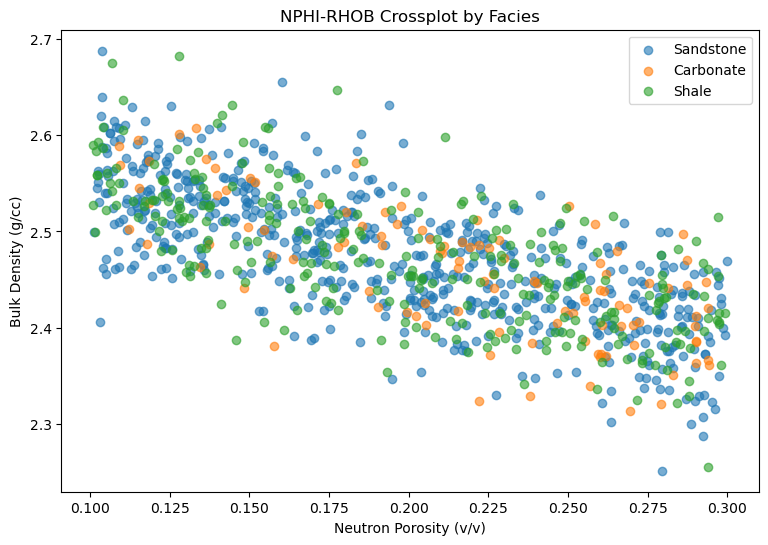

In [3]:
plt.figure(figsize=(9,6))
for facies in df['Facies'].unique():
    subset = df[df['Facies'] == facies]
    plt.scatter(subset['NPHI'], subset['RHOB'], label=facies, alpha=0.6)
plt.title('NPHI-RHOB Crossplot by Facies')
plt.xlabel('Neutron Porosity (v/v)')
plt.ylabel('Bulk Density (g/cc)')
plt.legend()
plt.show()

# Hexbin Plots (For High-Density Data)

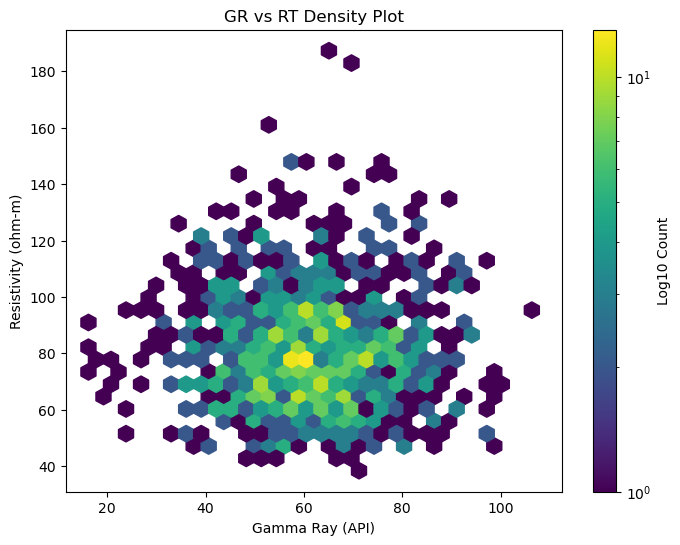

In [4]:
plt.figure(figsize=(8,6))
plt.hexbin(df['GR'], df['RT'], gridsize=30, cmap='viridis', bins='log')
plt.colorbar(label='Log10 Count')
plt.title('GR vs RT Density Plot')
plt.xlabel('Gamma Ray (API)')
plt.ylabel('Resistivity (ohm-m)')
plt.show()

# Pair Plots (Multi-Variable Relationships)

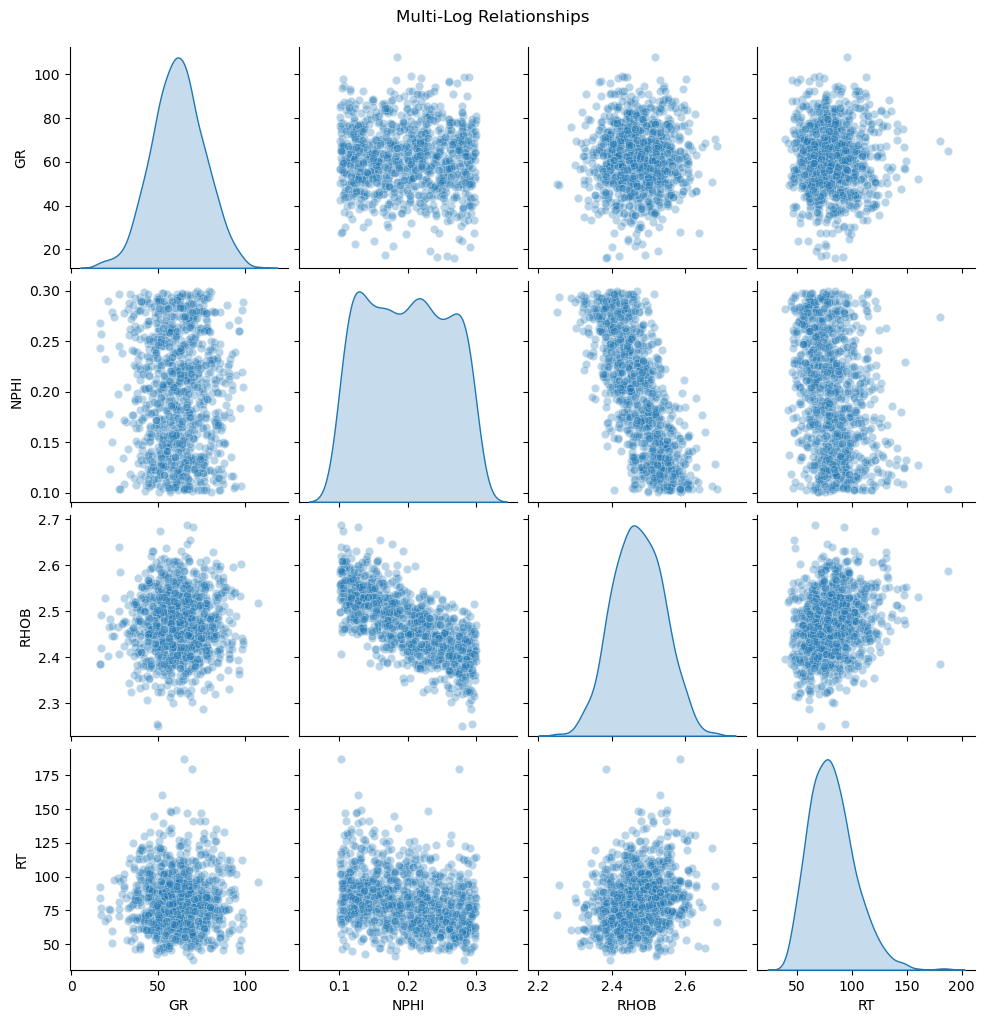

In [5]:
sns.pairplot(df[['GR','NPHI','RHOB','RT']], 
             diag_kind='kde', 
             plot_kws={'alpha':0.3})
plt.suptitle('Multi-Log Relationships', y=1.02)
plt.show()

# Crossplots with Regression

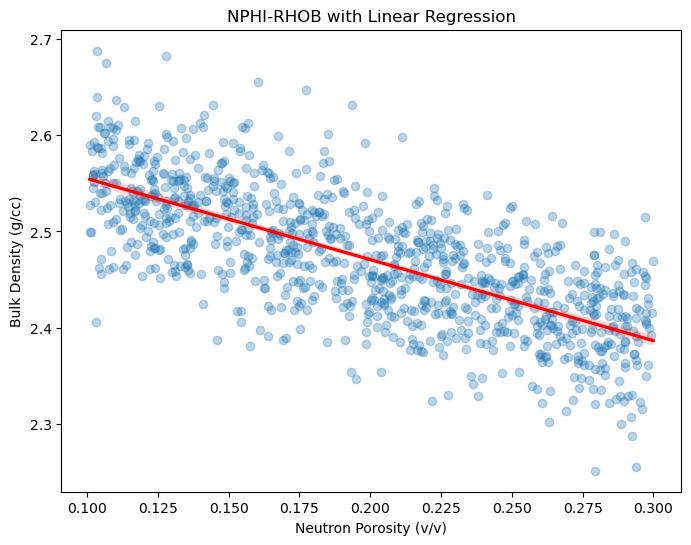

In [6]:
plt.figure(figsize=(8,6))
sns.regplot(data=df, x='NPHI', y='RHOB', 
            scatter_kws={'alpha':0.3},
            line_kws={'color':'red'})
plt.title('NPHI-RHOB with Linear Regression')
plt.xlabel('Neutron Porosity (v/v)')
plt.ylabel('Bulk Density (g/cc)')
plt.show()

# Faceted Plots by Category

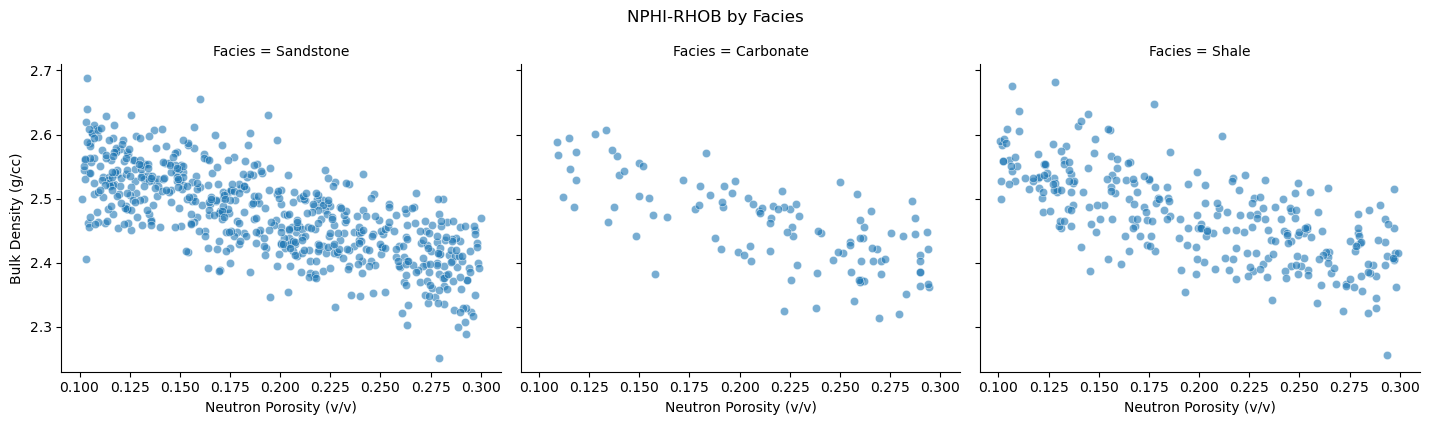

In [7]:
g = sns.FacetGrid(df, col='Facies', height=4, aspect=1.2)
g.map(sns.scatterplot, 'NPHI', 'RHOB', alpha=0.6)
g.set_axis_labels('Neutron Porosity (v/v)', 'Bulk Density (g/cc)')
g.fig.suptitle('NPHI-RHOB by Facies', y=1.05)
plt.show()

# Advanced: Density-Neutron Crossplot with Zonation

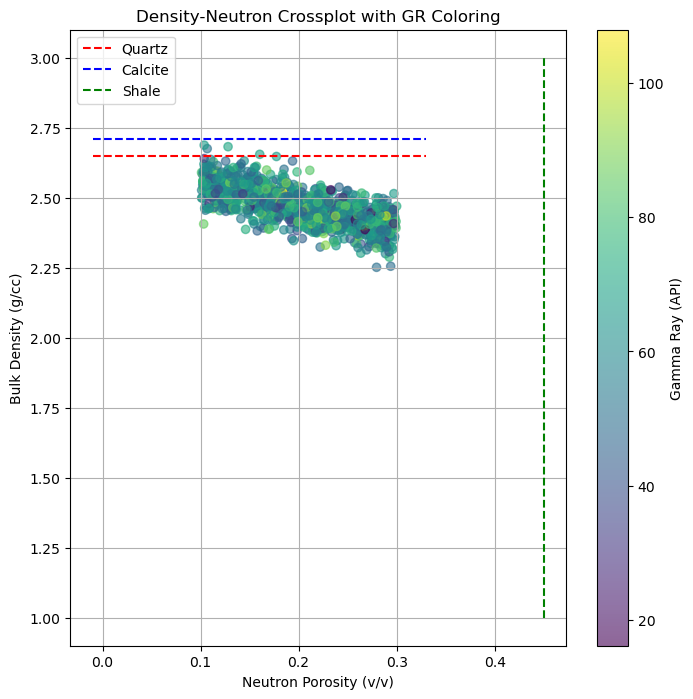

In [8]:
plt.figure(figsize=(8,8))

# Plot data points
sc = plt.scatter(df['NPHI'], df['RHOB'], c=df['GR'], 
                cmap='viridis', alpha=0.6)
plt.colorbar(sc, label='Gamma Ray (API)')

# Add typical mineral lines
plt.plot([-0.01, 0.33], [2.65, 2.65], 'r--', label='Quartz')  # Sandstone
plt.plot([-0.01, 0.33], [2.71, 2.71], 'b--', label='Calcite')  # Limestone
plt.plot([0.45, 0.45], [1.0, 3.0], 'g--', label='Shale')       # Shale point

plt.title('Density-Neutron Crossplot with GR Coloring')
plt.xlabel('Neutron Porosity (v/v)')
plt.ylabel('Bulk Density (g/cc)')
plt.legend()
plt.grid(True)
plt.show()

# Practical Petrophysics Applications

## Identify Fluid Contacts:

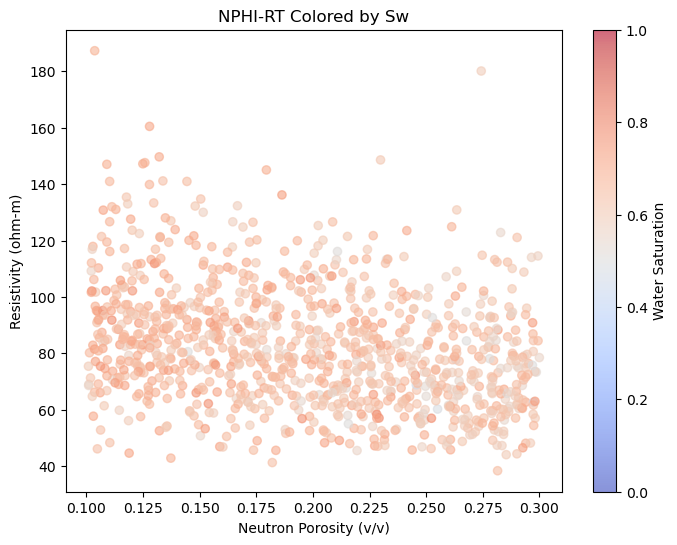

In [9]:
df['Sw'] = 0.7 - 0.3*df['NPHI'] + np.random.normal(0,0.05,1000)  # Synthetic Sw
plt.figure(figsize=(8,6))
plt.scatter(df['NPHI'], df['RT'], c=df['Sw'], cmap='coolwarm', 
           vmin=0, vmax=1, alpha=0.6)
plt.colorbar(label='Water Saturation')
plt.title('NPHI-RT Colored by Sw')
plt.xlabel('Neutron Porosity (v/v)')
plt.ylabel('Resistivity (ohm-m)')
plt.show()

## Highlight Outliers:

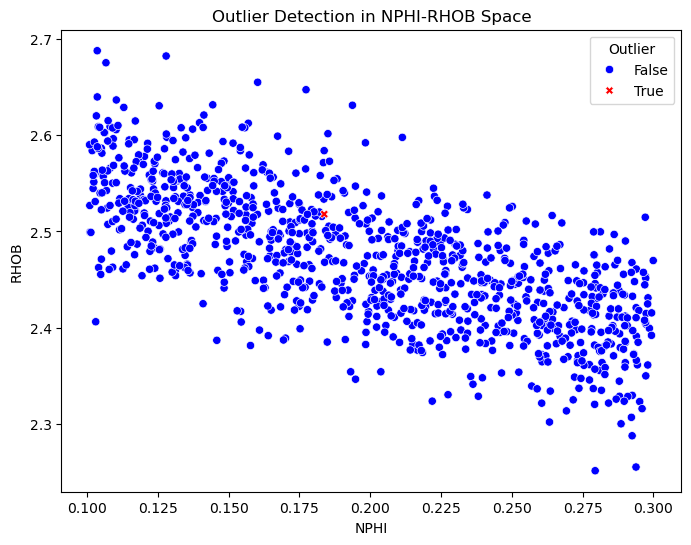

In [10]:
df['Outlier'] = (df['GR'] > 100) | (df['NPHI'] < 0.05)
plt.figure(figsize=(8,6))
sns.scatterplot(data=df, x='NPHI', y='RHOB', 
               hue='Outlier', style='Outlier',
               palette={True:'red', False:'blue'})
plt.title('Outlier Detection in NPHI-RHOB Space')
plt.show()